In [2]:
import pandas as pd
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

print(df.columns)

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')


In [3]:
task1 = df[['category', 'isBestSeller']]
print(task1)

                   category  isBestSeller
0            Hi-Fi Speakers         False
1            Hi-Fi Speakers          True
2            Hi-Fi Speakers         False
3            Hi-Fi Speakers         False
4            Hi-Fi Speakers         False
...                     ...           ...
2443646  Motorbike Clothing         False
2443647  Motorbike Clothing         False
2443648  Motorbike Clothing         False
2443649  Motorbike Clothing         False
2443650  Motorbike Clothing         False

[2443651 rows x 2 columns]


In [4]:
crosst = pd.crosstab(df['category'], df['isBestSeller'])
print(crosst)

isBestSeller                    False  True 
category                                    
3D Printers                       247      1
3D Printing & Scanning           4065      2
Abrasive & Finishing Products     245      5
Action Cameras                   1696      1
Adapters                          251      3
...                               ...    ...
Wind Instruments                  243      7
Window Treatments                 234      5
Women                           17559    213
Women's Sports & Outdoor Shoes   1939     20
eBook Readers & Accessories       246      0

[296 rows x 2 columns]


In [5]:
crosst_order = crosst.sort_values(by= True, ascending=False)
print(crosst_order)

isBestSeller                  False  True 
category                                  
Grocery                        9008    556
Health & Personal Care         9017    552
Baby                          14709    341
Sports & Outdoors            835935    330
Power & Hand Tools             8353    306
...                             ...    ...
Blank Media Cases & Wallets     243      0
Boating Footwear                140      0
Boxes & Organisers              911      0
CD, Disc & Tape Players        8798      0
eBook Readers & Accessories     246      0

[296 rows x 2 columns]


In [6]:
crosst_order.to_excel("crosstab_by_true_count.xlsx", sheet_name="crosstab", index=True)

In [7]:
chi2, p, dof, expected = chi2_contingency(crosst)

print("chi2 =", chi2)
print("p-value =", p)
print("dof =", dof)
print("expected frequencies (array) =\n", expected)

chi2 = 36540.20270061387
p-value = 0.0
dof = 295
expected frequencies (array) =
 [[2.47190130e+02 8.09870149e-01]
 [4.05371878e+03 1.32812173e+01]
 [2.49183599e+02 8.16401360e-01]
 [1.69145827e+03 5.54173243e+00]
 [2.53170536e+02 8.29463782e-01]
 [8.50214439e+03 2.78556144e+01]
 [1.06650580e+02 3.49419782e-01]
 [2.57157474e+02 8.42526204e-01]
 [9.51781673e+03 3.11832664e+01]
 [1.50008526e+04 4.91473619e+01]
 [9.32544700e+03 3.05530045e+01]
 [2.38219520e+02 7.80479700e-01]
 [3.22941944e+03 1.05805616e+01]
 [9.44704859e+03 3.09514084e+01]
 [6.68808779e+03 2.19122125e+01]
 [5.26275760e+02 1.72423967e+00]
 [1.90296531e+04 6.23469391e+01]
 [2.77191835e+03 9.08164873e+00]
 [2.53170536e+02 8.29463782e-01]
 [4.04674164e+02 1.32583581e+00]
 [1.92489346e+04 6.30653723e+01]
 [3.10482764e+03 1.01723609e+01]
 [2.04330551e+02 6.69449115e-01]
 [6.28839730e+03 2.06027047e+01]
 [5.23385231e+03 1.71476942e+01]
 [9.52180367e+03 3.11963288e+01]
 [2.48186864e+02 8.13135755e-01]
 [9.46598655e+03 3.10134549e

In [8]:
# p is lower that 0.05, there is relationship between 'category' and 'isBestSeller'

In [9]:
import numpy as np
n = crosst.values.sum()
chi2 = 36540.20270061387
r, k = crosst.shape
cramers_v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
print("Cramér's V =", cramers_v)

Cramér's V = 0.1222829439760564


In [10]:
# 0.1–0.3 for Cramér's V mean that relationship is pretty weak (pbbly not every cat showing equil proportions of bestseller)

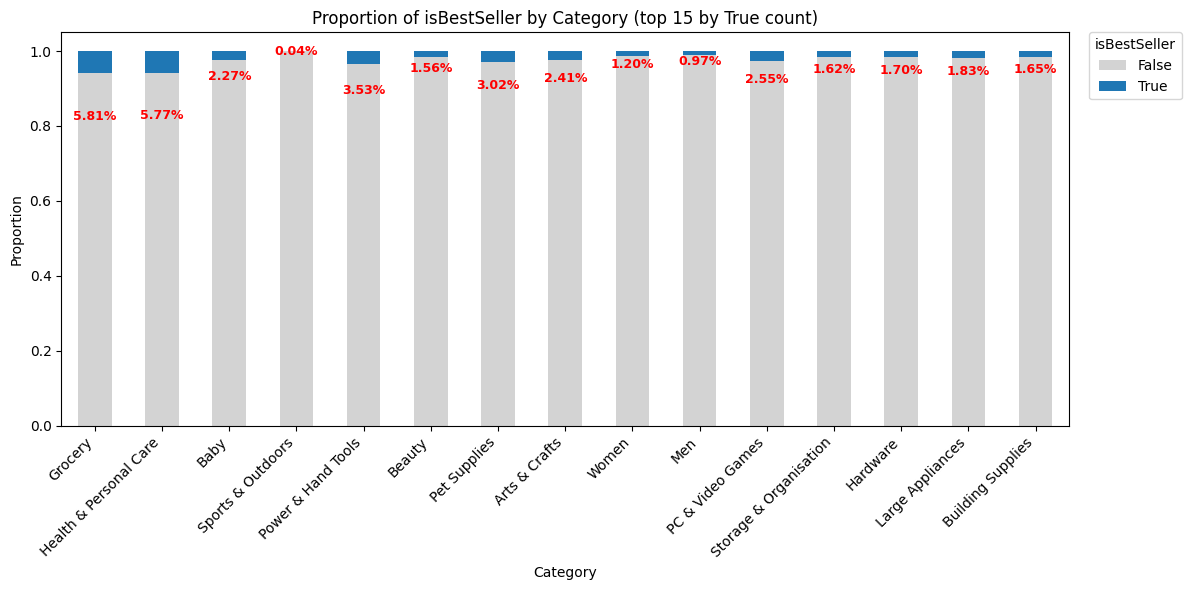

In [11]:
top_n = 15


crosst = pd.crosstab(df['category'], df['isBestSeller'])


true_col = True if True in crosst.columns else (1 if 1 in crosst.columns else crosst.columns[-1])
top_by_true = crosst[true_col].nlargest(top_n).index


df_plot = df[df['category'].isin(top_by_true)]


ct = pd.crosstab(df_plot['category'], df_plot['isBestSeller'])
ct_sorted = ct.sort_values(by=true_col, ascending=False)


ct_pct = ct_sorted.div(ct_sorted.sum(axis=1), axis=0)


colors = ['#d3d3d3', '#1f77b4']
ax = ct_pct.plot(kind='bar', stacked=True, figsize=(12,6), color=colors)

ax.set_ylabel('Proportion')
ax.set_xlabel('Category')
ax.set_title(f'Proportion of isBestSeller by Category (top {top_n} by True count)')


ax.legend(title='isBestSeller', loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)


true_col_plot = True if True in ct_pct.columns else (1 if 1 in ct_pct.columns else ct_pct.columns[-1])
idx_true = list(ct_pct.columns).index(true_col_plot)
true_vals = ct_pct[true_col_plot].values
bottoms = ct_pct.iloc[:, :idx_true].sum(axis=1).values if idx_true > 0 else np.zeros(len(ct_pct))
x = np.arange(len(ct_pct))

for xi, b, v in zip(x, bottoms, true_vals):
    if v > 0:
        y = b + v * -2  
        ax.text(xi, y, f"{v*100:.2f}%", ha='center', va='center', color='red', fontsize=9, fontweight='bold')

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()



In [12]:
df11 = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [13]:
df11 = df11.dropna(subset=['price'])

Q1 = df11['price'].quantile(0.25)
Q3 = df11['price'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

mask = df11['price'].between(lower_bound, upper_bound)

df11_clean = df11[mask].reset_index(drop=True)

In [14]:
prcat = df11_clean.groupby('category')['price'].count().reset_index(name='count')
prcat = prcat.sort_values(by= 'count' , ascending=False)
print(prcat)

                                   category   count
262                       Sports & Outdoors  694092
20                                   Beauty   19233
16                              Bath & Body   19050
177            Manicure & Pedicure Products   18904
116  Handmade Clothing, Shoes & Accessories   18811
..                                      ...     ...
108                          Graphics Cards      57
255                          Smart Speakers      49
6                    Alexa Built-In Devices      39
0                               3D Printers      36
200     Motorbike Exhaust & Exhaust Systems      28

[296 rows x 2 columns]


C:\Users\nicke\AppData\Local\Temp\ipykernel_23132\4181407263.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
C:\Users\nicke\AppData\Local\Temp\ipykernel_23132\4181407263.py:8: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='count'` for the same effect.
  ax = sns.violinplot(


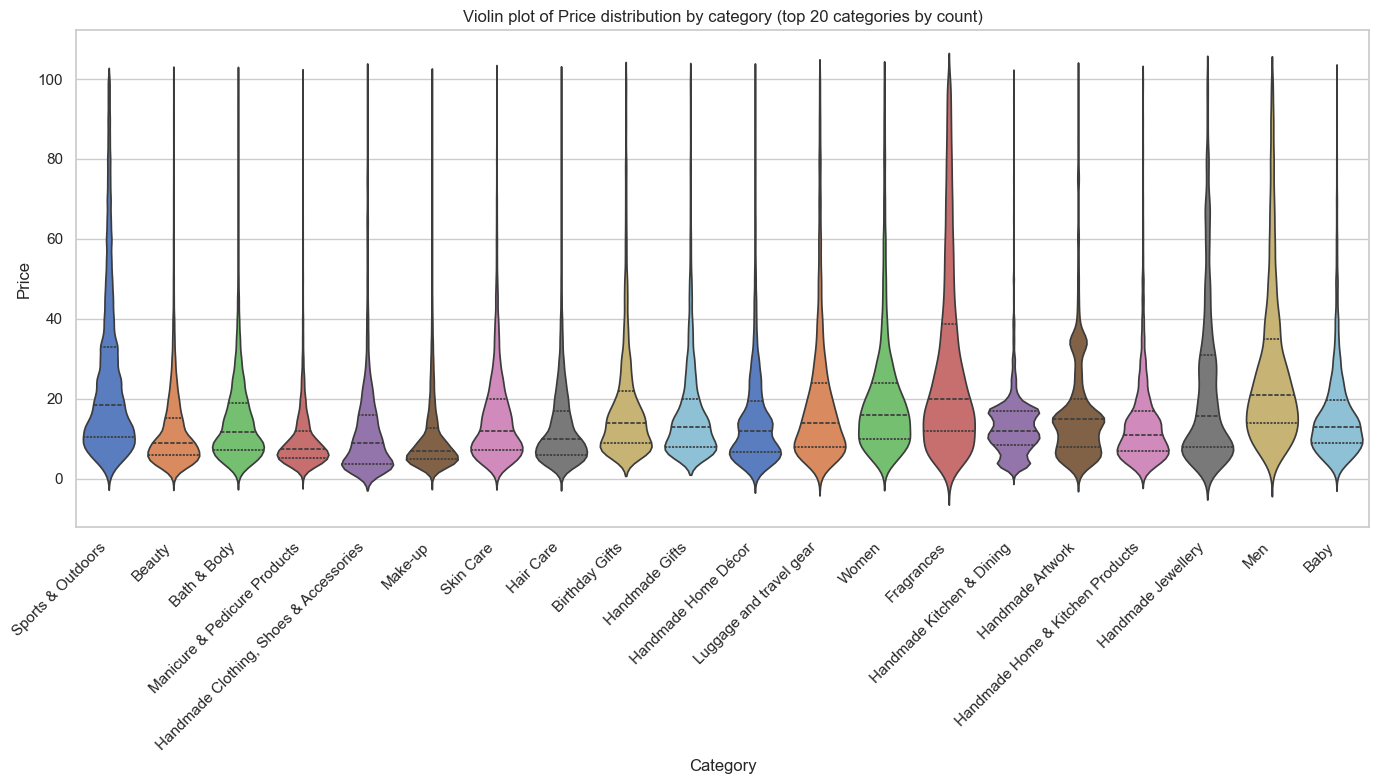

In [15]:
top_n = 20
top_cats = df11_clean['category'].value_counts().nlargest(top_n).index
df_viz = df11_clean[df11_clean['category'].isin(top_cats)].copy()

plt.figure(figsize=(14,8))
sns.set(style="whitegrid")

ax = sns.violinplot(
    data=df_viz,
    x='category',
    y='price',       
    order=top_cats,      
    inner='quartile',
    scale='count',
    palette='muted'
)

ax.set_xlabel('Category')
ax.set_ylabel('Price')   
ax.set_title(f'Violin plot of Price distribution by category (top {top_n} categories by count)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [16]:
prcatmed = df11_clean.groupby('category')['price'].median().reset_index(name='median')
prcatmed = prcatmed.sort_values(by= 'median' , ascending=False)
print(prcatmed)

                  category  median
75             Desktop PCs   74.00
34            Boxing Shoes   69.79
274                Tablets   69.00
108         Graphics Cards   68.54
190           Motherboards   67.92
..                     ...     ...
4                 Adapters    7.05
176                Make-up    7.00
246        Signs & Plaques    6.99
8            Arts & Crafts    5.99
209  Office Paper Products    4.37

[296 rows x 2 columns]


C:\Users\nicke\AppData\Local\Temp\ipykernel_23132\2997910057.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=mean_prices.values, y=mean_prices.index, palette="viridis")


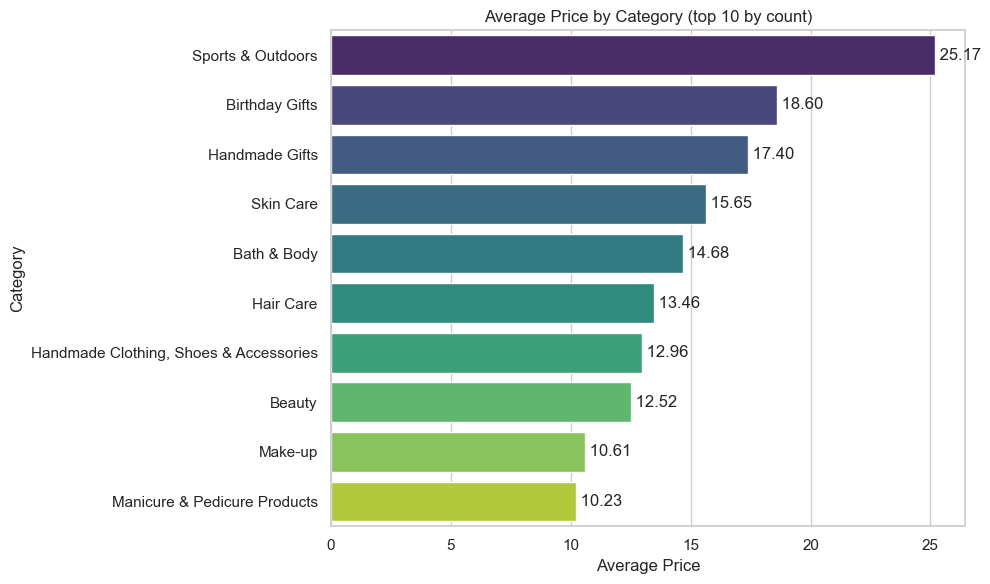

In [17]:
top_n = 10

top_cats = df11_clean['category'].value_counts().nlargest(top_n).index
df_top = df11_clean[df11_clean['category'].isin(top_cats)].copy()

mean_prices = df_top.groupby('category')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(10,6))
sns.set(style="whitegrid")
ax = sns.barplot(x=mean_prices.values, y=mean_prices.index, palette="viridis")

ax.set_xlabel("Average Price")
ax.set_ylabel("Category")
ax.set_title(f"Average Price by Category (top {top_n} by count)")

for i, v in enumerate(mean_prices.values):
    ax.text(v, i, f" {v:.2f}", va='center')

plt.tight_layout()
plt.show()

In [18]:
crossts = pd.crosstab(df['category'], df['stars'])
print(crossts)

stars                            0.0  1.0  1.1  1.2  1.3  1.4  1.5  1.6  1.7  \
category                                                                       
3D Printers                       87    4    0    0    0    0    0    1    0   
3D Printing & Scanning          3922    2    0    0    0    0    0    1    0   
Abrasive & Finishing Products     16    0    0    0    0    0    0    0    0   
Action Cameras                  1132    6    0    0    0    0    1    0    3   
Adapters                          11    0    0    0    0    0    0    0    0   
...                              ...  ...  ...  ...  ...  ...  ...  ...  ...   
Wind Instruments                 127    1    0    0    0    0    0    0    1   
Window Treatments                 14    0    0    0    0    0    0    0    0   
Women                            286   18    0    0    0    0    2    1    0   
Women's Sports & Outdoor Shoes   170    2    0    0    0    0    0    1    1   
eBook Readers & Accessories      137    

C:\Users\nicke\AppData\Local\Temp\ipykernel_23132\984429875.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(data=df_viz, x='category', y='stars', order=top_cats, palette='dark')


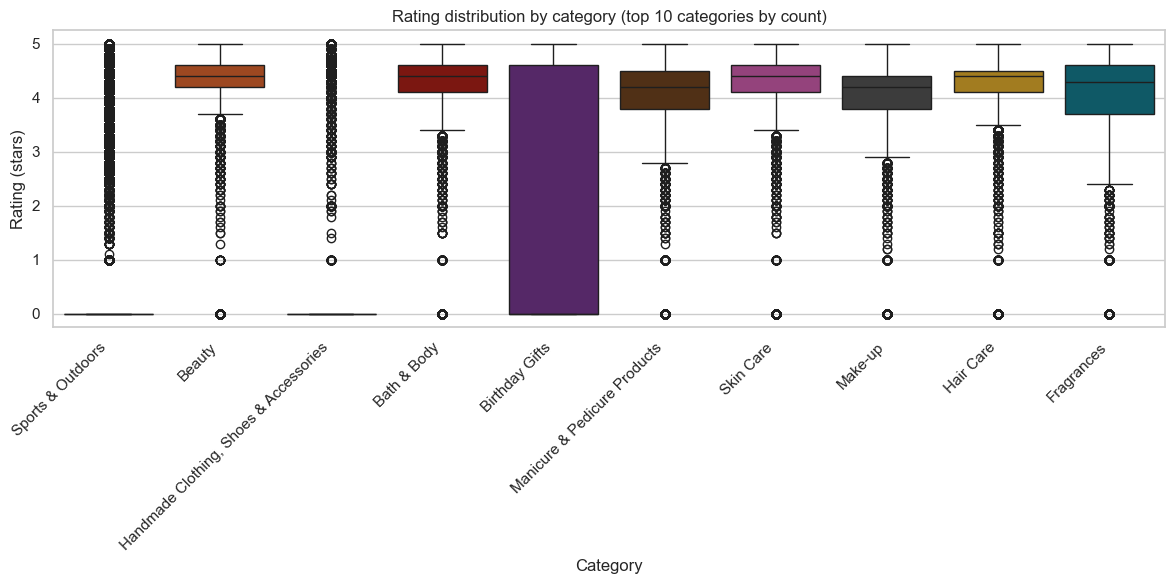

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

top_n = 10

df11_clean = df11.dropna(subset=['stars', 'category'])

top_cats = df11_clean['category'].value_counts().nlargest(top_n).index
df_viz = df11_clean[df11_clean['category'].isin(top_cats)].copy()

plt.figure(figsize=(12,6))
ax = sns.boxplot(data=df_viz, x='category', y='stars', order=top_cats, palette='dark')
ax.set_xlabel('Category')
ax.set_ylabel('Rating (stars)')
ax.set_title(f'Rating distribution by category (top {top_n} categories by count)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [23]:
medians = df11.groupby('category')['stars'].median().sort_values(ascending=False)
print(medians.head(10))

category
Computer Memory                 4.7
CPUs                            4.6
Building & Construction Toys    4.6
Laptop Accessories              4.6
Hobbies                         4.6
Kids' Play Figures              4.6
Beer, Wine & Spirits            4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Children's Bedding              4.5
Name: stars, dtype: float64


In [25]:
from scipy.stats import pearsonr, spearmanr

pearson_r, pearson_p = pearsonr(df11['price'], df11['stars'])

spearman_r, spearman_p = spearmanr(df11['price'], df11['stars'])

print(f"n = {len(df11)}")
print(f"Pearson r = {pearson_r:.4f}, p = {pearson_p:.4e}")
print(f"Spearman rho = {spearman_r:.4f}, p = {spearman_p:.4e}")

n = 2443651
Pearson r = -0.1249, p = 0.0000e+00
Spearman rho = -0.1332, p = 0.0000e+00


In [ ]:
#negative weak relationship the higher the price the slightly lower ranked, meaning higher prices cauasing higher expectations

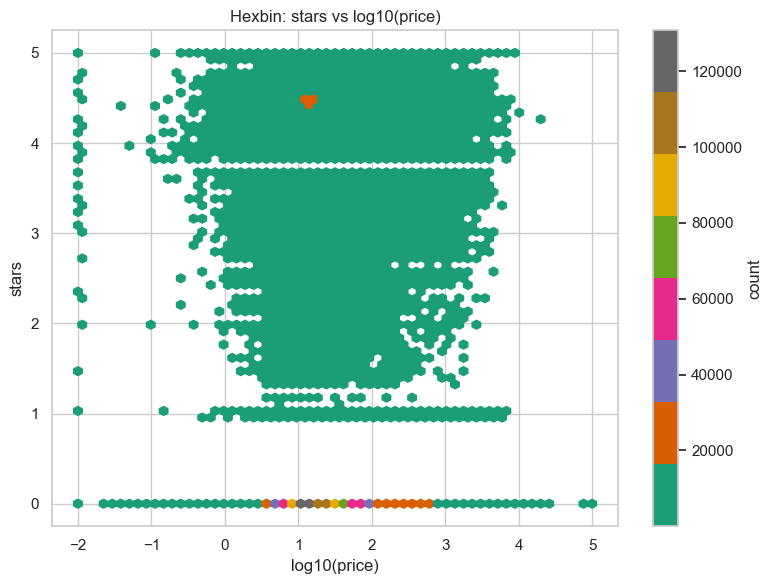

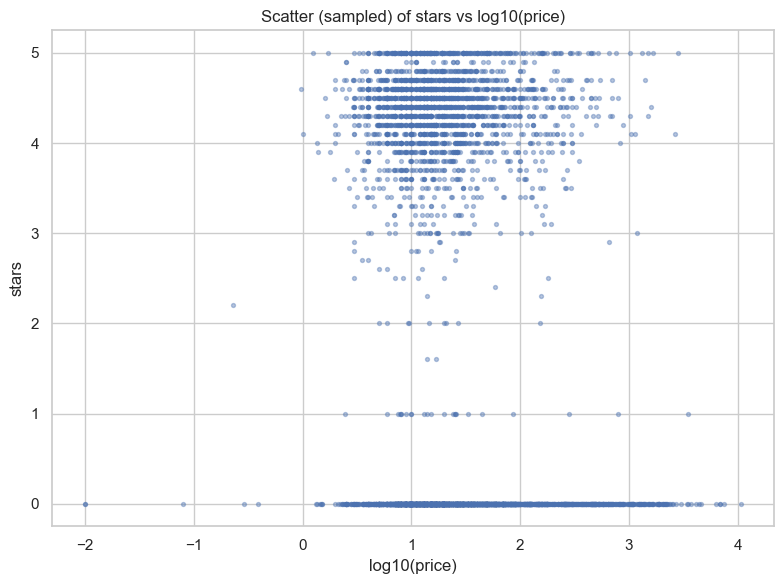

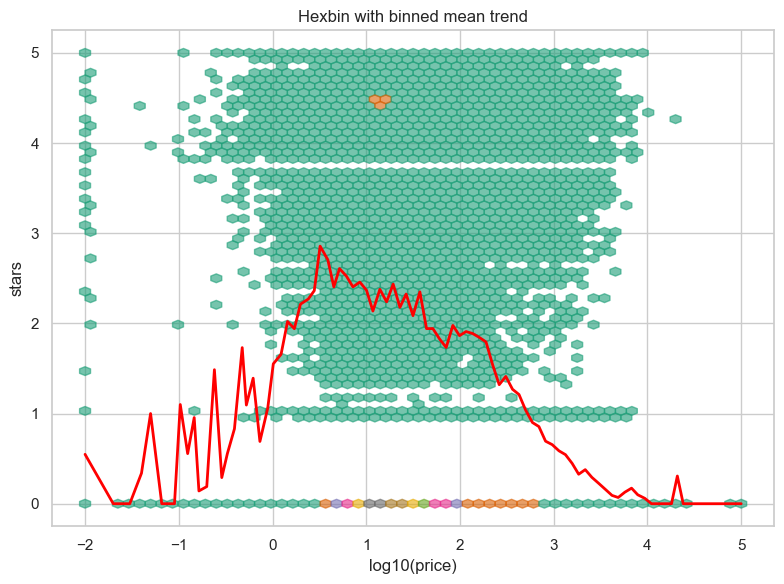

In [42]:

df11['log_price'] = np.log10(df11['price'].clip(lower=0.01))

# 1
plt.figure(figsize=(8,6))
plt.hexbin(df11['log_price'], df11['stars'], gridsize=60, cmap='Dark2', mincnt=1)
plt.colorbar(label='count')
plt.xlabel('log10(price)')
plt.ylabel('stars')
plt.title('Hexbin: stars vs log10(price)')
plt.tight_layout()
plt.show()

# 2
sample = df11.sample(n=5000, random_state=1) if len(df11) > 5000 else df11
plt.figure(figsize=(8,6))
plt.scatter(sample['log_price'], sample['stars'], s=8, alpha=0.4)
plt.xlabel('log10(price)')
plt.ylabel('stars')
plt.title('Scatter (sampled) of stars vs log10(price)')
plt.tight_layout()
plt.show()

n_bins = 100
bins = np.linspace(df11['log_price'].min(), df11['log_price'].max(), n_bins)
df11['bin'] = np.digitize(df11['log_price'], bins)
trend = df11.groupby('bin').agg(log_price_mean=('log_price','mean'), stars_mean=('stars','mean')).dropna()

plt.figure(figsize=(8,6))
plt.hexbin(df11['log_price'], df11['stars'], gridsize=60, cmap='Dark2', mincnt=1, alpha=0.6)
plt.plot(trend['log_price_mean'], trend['stars_mean'], color='red', linewidth=2)
plt.xlabel('log10(price)')
plt.ylabel('stars')
plt.title('Hexbin with binned mean trend')
plt.tight_layout()
plt.show()

In [43]:
df11.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 11 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
 9   log_price          float64
 10  bin                int64  
dtypes: bool(1), float64(3), int64(4), str(3)
memory usage: 188.8 MB


In [45]:
df12 = pd.read_csv("amz_uk_price_prediction_dataset.csv")

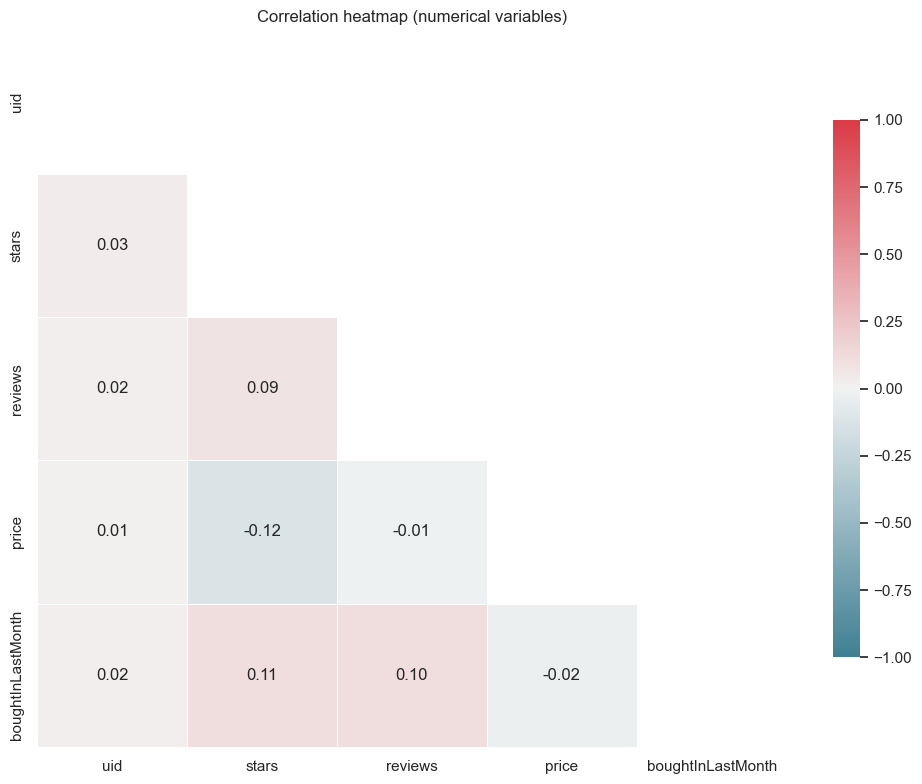

In [46]:

num = df12.copy()
for col in ['price', 'stars', 'reviews', 'boughtInLastMonth']:
    if col in num.columns:
        num[col] = pd.to_numeric(num[col], errors='coerce')

num = num.select_dtypes(include=[np.number])

corr = num.corr()

mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10,8))
sns.set(style="white")
cmap = sns.diverging_palette(220, 10, as_cmap=True)
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=1.0, vmin=-1.0, center=0,
            annot=True, fmt=".2f", square=False, linewidths=.5, cbar_kws={"shrink": .75})
plt.title("Correlation heatmap (numerical variables)")
plt.tight_layout()
plt.show()

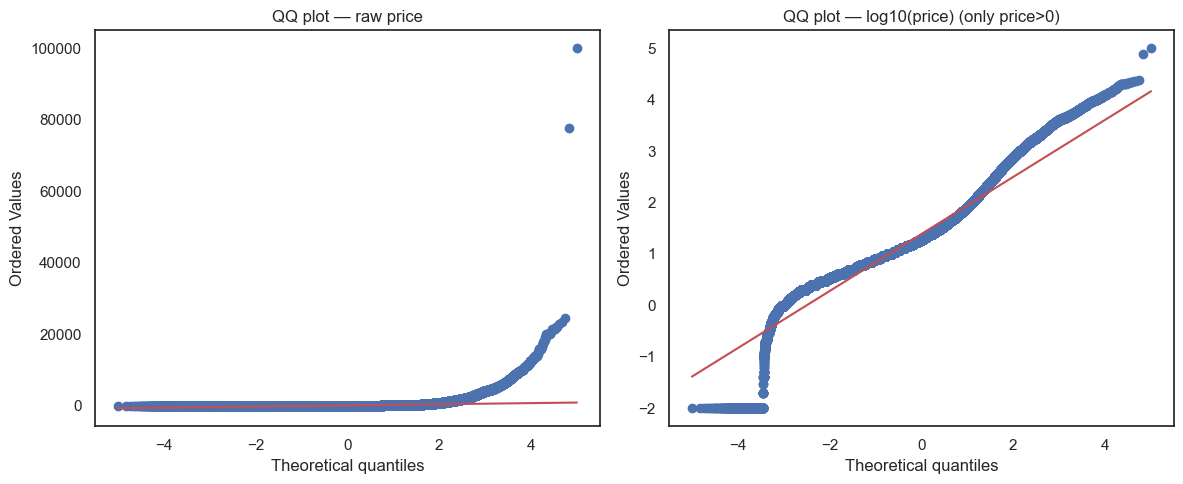

In [48]:
from scipy import stats

prices = pd.to_numeric(df12['price'], errors='coerce').dropna()


prices_pos = prices[prices > 0]

plt.figure(figsize=(12,5))


plt.subplot(1,2,1)
stats.probplot(prices, dist="norm", plot=plt)
plt.title("QQ plot — raw price")


plt.subplot(1,2,2)
stats.probplot(np.log10(prices_pos), dist="norm", plot=plt)
plt.title("QQ plot — log10(price) (only price>0)")

plt.tight_layout()
plt.show()